# OSEMN Exercises

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import random

1\. Create a random list of number and then save it to a text file named "simple_data.txt"

In [2]:
rand_list = random.sample(range(1,1000), 700)

file_name = "simple_data.txt"

with open(file_name, mode='w') as f:
    for i in rand_list:
        f.write(str(i) + '\n')
    

2\. Create a random matrix of 5x5 and then save it to a text file named "data.txt"

In [3]:
matrix5 = np.random.random((5,5))

with open("data.txt", mode='w') as f:
    for row in matrix5:
        for dato in row:
            f.write(str(dato) + ' ')
        f.write('\n')

3\. Load the saved txt file of point 2 and convert it to a csv file (by hand)

In [ ]:
# primero leemos el archivo y guardamos los datos en data
with open("data.txt", mode="r") as f:
    data = f.readlines() 

# Creamos y escribimos el archivo .csv similar al ejercicio 1, en modo escritura
with open("data.csv", mode="w") as f:
    for line in data: # para linea en data
        values = line.split() #spliteamos las lineas
        f.write(",".join(values) + "\n") # escribimos los valores en el archivo .csv y lo separamos por comas

4\. load the binary file named *credit_card.dat* and convert the data into the real credit-card number.
Each line correspond to a credit card number.
Each character is composed by 6 bit (even the space) and the last 4 bit are just a padding

**hint**: use the `chr()` function to convert a number to a char

In [ ]:
with open("credit_card.dat", mode="rb") as f: # en este caso como el archivo esta en binario el modo es rb
    data = f.readlines()

for line in data: # luego para cada linea de datos
    bits = ''.join(format(byte, '08b') for byte in line) # separamos cada byte 
    # format(byte, '08b'): convierte cada byte en una cadena binaria de 8 bits.
    # y unimos los bytes despues para tener una sola cadena
    bits = bits[:-4] # quitamos los ultimos cuatro bits que son de padding

    card_number = '' # inicializamos la cadena que va a guardar el numero de tarjeta

    for i in range(0, len(bits), 6): # para i de 0 a len bits en pasos de 6 en 6
        number = int(bits[i:i+6], 2) # convertimos los bits a decimal, ya que con el 2 le decimos a python que el numero esta en binario 
        # por lo que lo pasamos a decimal 
        card_number += chr(number) # y vamos agragando el numero de la tarjeta a la cadena que ya teniamos en blanco 

    print(card_number) # imprimmos los resultados

5\. Load the file "user_data.json", filter the data by the "CreditCardType" field equals to "American Express". Than save the data a to CSV.

In [ ]:
import json
import csv

# Cargamos el archivo JSON
with open("user_data.json", mode = "r") as f:
    data = json.load(f) # aqui unicamente con json.load es suficiente no tenemos que readlines

# creamos un array para guardar los datos seleciconados
filtered_data = []

# para cada usuario en los datos
for user in data:
    if user["CreditCardType"] == "American Express": # si el ususario tiene American Express en su campo de CerditCardType
        filtered_data.append(user) # agregamos al usuario a el array de filtrados

# Guardamos la data filtrada a un .csv
with open("american_express.csv", mode = w) as f:
    # esto es para escribir los nombres de las columnas
    headers = filtered_data[0].keys()
    f.write(",".join(headers) + "\n") # separado por comas y dejando espacio

    # Escribimos los datos de los ususarios
    for user in filtered_data: # para usuiaro en los datos filtrados
        values = [str(value) for value in user.values()] # ponemos en un array los valores usando user.values()
        # agregamos cada valor del usuario en un values como una string
        f.write(",".join(values) + "\n") # escribimos los valores separados por una coma e identados

6\. Load the file from this url: [https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1](https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1) with Pandas. 
+ Explore the data (see the info of the data)
+ Draw the istogram of the 'class' field. Decribe wath yuou see


In [14]:
import pandas as pd

url = "https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1"

# con pandas c+poedmos leer directamente un archivo desde una url
data = pd.read_csv(url)

data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,7,7,0,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,7,7,0,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,7,7,0,2,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,7,7,0,2,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,7,7,0,2,1,0,3,0,1


In [15]:
data.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,...,8124.000000,8124.000000,8124.000000,8124.0,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000,8124.000000
mean,0.482029,3.348104,1.827671,4.504677,0.415559,4.144756,0.974151,0.161497,0.309207,4.810684,...,1.603644,5.816347,5.794682,0.0,1.965534,1.069424,2.291974,3.596750,3.644018,1.508616
std,0.499708,1.604329,1.229873,2.545821,0.492848,2.103729,0.158695,0.368011,0.462195,3.540359,...,0.675974,1.901747,1.907291,0.0,0.242669,0.271064,1.801672,2.382663,1.252082,1.719975
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000,3.000000,0.000000,2.000000,1.000000,0.000000,0.000000,2.000000,...,1.000000,6.000000,6.000000,0.0,2.000000,1.000000,0.000000,2.000000,3.000000,0.000000
50%,0.000000,3.000000,2.000000,4.000000,0.000000,5.000000,1.000000,0.000000,0.000000,5.000000,...,2.000000,7.000000,7.000000,0.0,2.000000,1.000000,2.000000,3.000000,4.000000,1.000000
75%,1.000000,5.000000,3.000000,8.000000,1.000000,5.000000,1.000000,0.000000,1.000000,7.000000,...,2.000000,7.000000,7.000000,0.0,2.000000,1.000000,4.000000,7.000000,4.000000,2.000000
max,1.000000,5.000000,3.000000,9.000000,1.000000,8.000000,1.000000,1.000000,1.000000,11.000000,...,3.000000,8.000000,8.000000,0.0,3.000000,2.000000,4.000000,8.000000,5.000000,6.000000


In [ ]:
# asi podemos contar el numero de clases diferentes que contiene la varibale class y cuantos hay en cada clase
data["class"].value_counts()

class
0    4208
1    3916
Name: count, dtype: int64

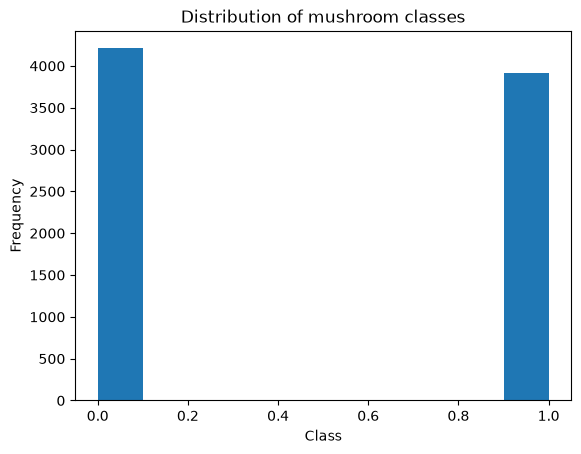

In [20]:
import matplotlib.pyplot as plt

#simplemente utilizamos .hist y ponemos la colmumna que queremos plotear
plt.hist(data["class"])
plt.xlabel("Class")
plt.ylabel("Frequency")
plt.title("Distribution of mushroom classes")
plt.show()

7\. Load the remote file [https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1](https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1) with Pandas and plot a scatter plot all possible combination of the following fields:
    
  + features_1
  + features_2
  + features_3

In [23]:
data = pd.read_csv("https://www.dropbox.com/s/vkl89yce7xjdq4n/regression_generated.csv?dl=1")
data.head()

,label,features_1,features_2,features_3,features_4,features_5,features_6,features_7,features_8,features_9,...,features_11,features_12,features_13,features_14,features_15,features_16,features_17,features_18,features_19,features_20
0,-89.243497,2.175170,-0.285786,-0.603396,-0.627453,-0.686474,0.381067,0.306205,-0.637447,-1.332087,...,1.290725,1.047483,-1.055467,0.853204,0.038665,-0.752959,0.577920,-0.657400,1.367308,0.570199
1,230.050125,1.481941,-1.327870,-0.543583,-0.303578,1.552964,0.549738,-0.763094,-0.455796,2.053388,...,-1.761306,-0.934284,-1.050999,0.444026,-0.037959,1.061624,-1.569870,2.410696,1.113594,2.329479
2,-286.844411,-1.154394,-0.178649,-1.636646,0.239353,-0.684994,0.587201,-0.209564,-0.428956,-0.757998,...,0.374645,-1.702189,-0.014514,-0.711557,-0.558523,-1.204526,0.234989,0.398384,-0.236555,0.642003
3,364.552862,0.197665,1.455707,1.562205,2.168207,0.053335,0.790492,-0.212023,-1.142483,-1.124906,...,0.712160,-2.844936,0.483994,-0.694294,1.349605,-1.303414,0.161987,0.754084,1.248258,-1.466045
4,515.460006,0.596676,0.969860,1.294158,-0.404728,2.145297,0.997481,-0.541670,-0.952850,-0.592084,...,-1.347072,0.243422,0.290336,0.798331,0.876428,-0.366807,-0.119534,0.892320,-0.806912,0.736080


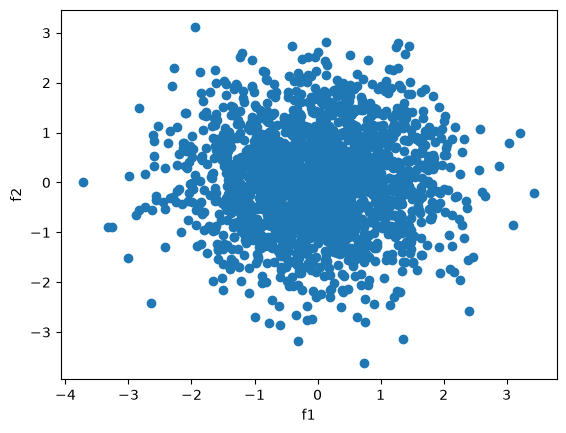

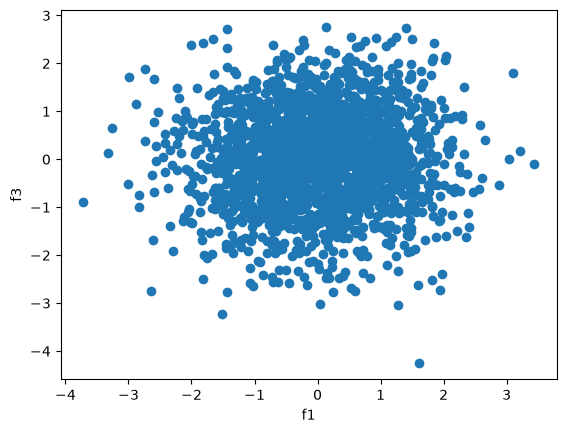

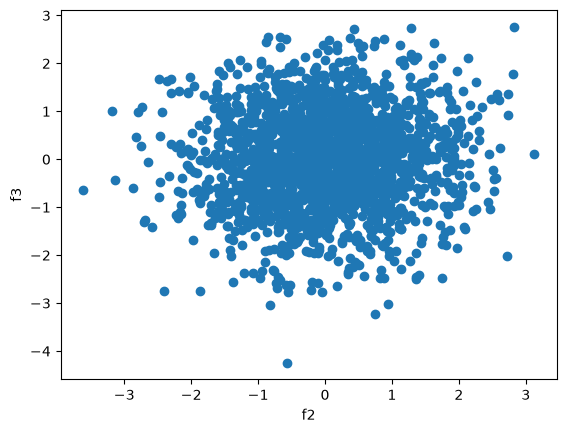

In [26]:
# definimos variables a plotear
f1 = data["features_1"]
f2 = data["features_2"]
f3 = data["features_3"]

plt.scatter(f1,f2)
plt.xlabel("f1")
plt.ylabel("f2")
plt.show()

plt.scatter(f1,f3)
plt.xlabel("f1")
plt.ylabel("f3")
plt.show()

plt.scatter(f2,f3)
plt.xlabel("f2")
plt.ylabel("f3")
plt.show()

8\. Load the same file of point 6, and convert the file to json with Pandas.

In [31]:
url = "https://www.dropbox.com/s/7u3lm737ogbqsg8/mushrooms_categorized.csv?dl=1"

# con pandas podemos leer directamente un archivo desde una url
data = pd.read_csv(url)

json_mush = data.to_json("json_mush.json")